# Central humans against central agents

Human players who wait centrally, against RL agents that do the same. The strategy is held fixed,
so what is left is how each side *plays* it.

The agents are the **260914** batch, 30 social self-play models. That batch is the one to use: its
training fixes (gamma 0.99 to 0.998, `time_horizon` 128 to 512, constant schedules, 7e6 steps)
removed the strategy split, and 27 of 30 models now sit in one central cluster at onset centrality
0.81-0.91. Nothing here rests on a poorly-trained peripheral group.

The humans are the top 20% of players by mean slice-onset centrality, ranked within each session.

**The difficulty is that the two fingerprints are not measured the same way.** Three things have to
be fixed before any number is compared, and one cannot be fixed at all. Section 1 sets that out and
everything after it depends on it.

**Plan**
1. What can be compared, what has to be rebuilt, and what is dropped.
2. Position and perception.
3. Between-trial behaviour, once both sides are on one clock.
4. Execution and outcome.
5. P(High), and what the solo sessions say about it.
6. Whether the grouping rule changes any of it.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

import data_strings
import analysis.human_characterisation as hc
import analysis.model_characterisation as mc
import analysis.human_agent_comparison as hac

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 240)

RECOMPUTE = False               # rebuild the cached agent tables and the resampled ITI table
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', '260914')
OUTLIER_CUT = 0.75              # below the main band, which starts at 0.81 (matches the 260914 notebook)
N_BOOT = 2000                   # resamples for the interval on each difference
PRIMARY_SESSION = 'social'      # the task-matched human session; the solos are the control in part 5

HUMAN_COLOUR, AGENT_COLOUR = '#4a3aa7', '#8C8C8C'

## Load data

The human side comes from the cached fingerprint tables. The agent side runs `collect_model_data`
over the batch and then a second pass that resamples every agent onto the 30 Hz tick grid, both
cached, as together they take several minutes.

Two rebuilds happen here rather than later, because every section downstream uses them.

**Score.** The agent fingerprint's `score_rate` sums `winner_score`, which in self-play is the
model's whole output, while the human one sums the player's own score with a loss counting 0. The
agent side is recomputed per agent so both mean the same thing. Human score also drops forced
trials, which agents never see.

**Between-trial metrics.** Nothing is resampled. Each side stays at its own logging rate, for the
reason part 3a measures: the humans survive the tick grid untouched and the agents do not, so
matching grids would distort only the side that did not need it.

**Wall sensing.** Each side is measured on its own sensor. A human sees a continuous 110.36 degree
view, so the wedge model fits them. An agent does not: `SelectivePassThroughRaycast` casts **7 rays**
at 0, +/-18.3, +/-36.7 and +/-55 degrees, and a wall is sensed only where a ray lands on it, though a
ray hitting any part of a lit wall identifies the whole wall. Applying the wedge to agents would
credit them with a field of view they do not have, so the agent side uses
`analysis/agent_raycast.py`.

In [2]:
# build the human fingerprint: one row per player per session
onset = hc.load_tables()['onset']
players = hc.extreme_groups(hc.player_table(onset))
human_tables = hc.load_fingerprint_tables()
human_fp = hc.build_player_fingerprint(players, human_tables)

# put the human score on the agent trial mix (HighLow only) and the own-score definition
h_score = hac.human_score_metrics(human_tables['outcome'])
human_fp = human_fp.merge(h_score[list(hc.KEYS) + ['mean_score_own', 'score_rate_own']],
                          on=list(hc.KEYS), how='left')
human_fp['mean_score'] = human_fp['mean_score_own']
human_fp['score_rate'] = human_fp['score_rate_own']

print(f"human fingerprint: {human_fp.shape[0]} rows "
      f"({human_fp['session_type'].nunique()} sessions x {human_fp['experiment'].nunique()} experiments x 2 players)")

human_onset_tables: loaded from cache
human_fingerprint_tables: loaded from cache
human fingerprint: 600 rows (3 sessions x 100 experiments x 2 players)


In [3]:
# build the agent fingerprint over the batch, then apply the same two rebuilds
models = mc.get_batch_models(SIM_DATA_FOLDER)
tables = hac.load_agent_tables(SIM_DATA_FOLDER, models, recompute=RECOMPUTE)
iti_ticks = hac.load_agent_iti_ticks(SIM_DATA_FOLDER, models, recompute=RECOMPUTE)

usable = mc.summarise_collection(tables, models, verbose=False)
onset_by_model, gmm, boundary = mc.split_strategies(mc.onset_centrality_by_model(tables['slice']))
model_meta = mc.build_model_meta(usable, onset_by_model, strategy_col='strategy')
# hold the few off-cluster models out of every group statistic, as the 260914 notebook does
model_meta['group'] = np.where(model_meta['onset_centrality'] < OUTLIER_CUT, 'off-cluster', 'main')

agent_fp = mc.build_fingerprint(model_meta, tables)            # ITI metrics stay at 50 Hz, see part 3a

# measure agent wall-sensing with the ray sensor, not the human wedge. The agents have no continuous
# field of view: 7 rays at 0, +/-18.3, +/-36.7 and +/-55 degrees, and a wall counts as sensed only
# where a ray lands on it (analysis/agent_raycast.py)
ray_vis = hac.load_agent_ray_visibility(SIM_DATA_FOLDER, models, recompute=RECOMPUTE)
ray_by_model = hac.visibility_by_model(ray_vis).set_index('model')
PERCEPTION = [c for c in hac.PERCEPTION_METRICS if c in ray_by_model.columns]
agent_fp = agent_fp.set_index('model')
agent_fp.loc[ray_by_model.index, PERCEPTION] = ray_by_model[PERCEPTION]
agent_fp = agent_fp.reset_index()

a_score = hac.agent_own_score_metrics(tables['score'], tables['rt'])
agent_fp = agent_fp.merge(a_score[['model', 'score_rate_own']], on='model', how='left')
agent_fp['score_rate'] = agent_fp['score_rate_own']            # own score, not the winner's

agent = hac.agent_central_models(agent_fp)
BAND = hac.agent_band(agent)
human = human_fp.query("session_type == @PRIMARY_SESSION and group == 'central'")

# the sampling choice is stated in hac.COMPARABILITY and acted on here, so check the two agree
# rather than trusting them to stay in step. The agent ITI metrics must be the 50 Hz ones
native_check = tables['iti'].groupby('model')[hac.OWN_RATE_METRICS].mean()
assert np.allclose(agent_fp.set_index('model').loc[native_check.index, hac.OWN_RATE_METRICS],
                   native_check), "agent ITI metrics are not at their native rate"
assert set(hac.OWN_RATE_METRICS) == set(hac.ITI_METRICS), "own-rate labels drifted from ITI_METRICS"

print(f"agent central cluster: n = {len(agent)} of {len(agent_fp)} models, "
      f"onset centrality {BAND[0]:.3f} to {BAND[1]:.3f}")
print(f"human central ({PRIMARY_SESSION}): n = {len(human)} players, "
      f"onset centrality {human['onset_centrality'].min():.3f} to {human['onset_centrality'].max():.3f}")

agent_tables: loaded from cache
agent_iti_ticks: loaded from cache
agent_ray_visibility: loaded from cache
agent central cluster: n = 27 of 30 models, onset centrality 0.806 to 0.909
human central (social): n = 40 players, onset centrality 0.778 to 0.910


## 1. What can be compared

Every metric the two fingerprints share falls into one of four cases.

- **direct** - same definition, same clock. Comparable as it stands.
- **rebuilt** - comparable only after the recomputation done above.
- **own rate** - each side is left on its own logging rate rather than resampled to a shared one.
  This is the five between-trial metrics, and part 3a is the measurement that justifies it.
- **dropped** - not comparable, and not repaired.

The one dropped metric is `win_rate`. Agent self-play puts two copies of one model against each
other, so it is 0.5 by construction and carries no information about the model.

In [4]:
display(hac.comparability_table())

# a unit is a player on the human side and a model on the agent side
METRICS = hac.COMPARED_METRICS
comparison = hac.compare_metrics(human, agent, METRICS, n_boot=N_BOOT)
print(f"{len(METRICS)} metrics compared "
      f"({len(hac.DIRECT_METRICS)} direct, {len(hac.REBUILT_METRICS)} rebuilt, "
      f"{len(hac.OWN_RATE_METRICS)} at own rate), {len(hac.DROPPED_METRICS)} dropped")

,metric,status,reason,reading
0,winner_path_len,direct,"own wins on both sides, summed over logged frames",execution
1,path_ratio,direct,own wins on both sides; per-trial ratio then a...,execution
2,latency_to_reach_wall,direct,"median over own wins, from logged times",execution
3,frac_trials_over_5s,direct,share of own wins over 5 s,execution
4,p_high,direct,"own wins, High/Low trials only on both sides",execution
5,mean_score,direct,own score including losses on both sides (agen...,outcome
6,onset_centrality,direct,position at one frame; sampling rate does not ...,position
7,iti_centrality,direct,mean radius over the ITI; a mean is insensitiv...,position
8,score_rate,rebuilt,"agents sum winner_score, humans sum own score;...",outcome
9,frac_visible_at_onset,rebuilt,each side on its own sensor: human 110 deg wed...,perception


18 metrics compared (8 direct, 5 rebuilt, 5 at own rate), 1 dropped


**Three things are worth knowing before reading any of it.**

- **Agents never see forced trials.** `trialTypes = {"HighLow"}` in `GeneralGlobals.cs`, while 20%
  of human trials are forced. Human score metrics above are cut to HighLow trials to match.
- **Resampling the agents costs some apparent stillness.** A 30 Hz tick interpolates across a 50 Hz
  frame, so a tick spanning a still moment and a moving one reads as moving. It would be easy to
  assume this cancels, since humans pass through the same step from 48 Hz. It does not, and part 3
  measures how far it fails to.
- **Head pitch never enters.** `get_wall_visible` uses yaw only
  (`trajectory_vectors.py:107`), on both sides, so a human looking at the floor still counts as
  seeing a wall.

## 2. Position and sensing

Whether the two groups are standing in the same place, and whether they pick up the walls equally
fast when they light. If these differ, nothing downstream can be read as a difference in play.

Each side is measured on its own sensor, so "sensed" means something different for each: a wall
inside a human's 110.36 degree view, or a wall any of an agent's 7 rays lands on. The cell below
also shows what the agents would have scored under the human wedge, since that is what the batch
notebooks report and the gap is the size of the error in using it.

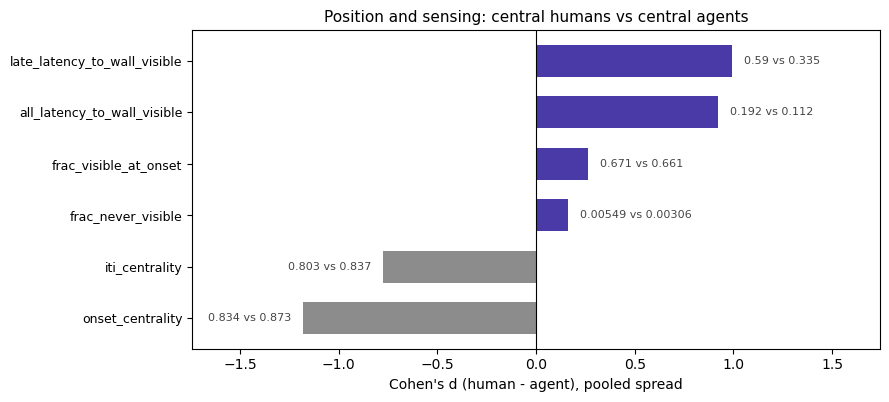

,metric,human_mean,agent_mean,diff,d,ci_lo,ci_hi
8,onset_centrality,0.834,0.873,-0.039,-1.182,-0.053,-0.024
9,late_latency_to_wall_visible,0.590,0.335,0.255,0.993,0.124,0.371
10,all_latency_to_wall_visible,0.192,0.112,0.080,0.923,0.038,0.120
11,iti_centrality,0.803,0.837,-0.034,-0.774,-0.054,-0.015
16,frac_visible_at_onset,0.671,0.661,0.010,0.262,-0.005,0.025
17,frac_never_visible,0.005,0.003,0.002,0.160,-0.003,0.010


,"agent, 7 rays","agent, 110 deg wedge","human, 110 deg wedge",wedge error on agents
frac_visible_at_onset,0.661,0.684,0.671,0.023
frac_never_visible,0.003,0.003,0.005,0.000
late_latency_to_wall_visible,0.335,0.341,0.590,0.006
all_latency_to_wall_visible,0.112,0.107,0.192,-0.005


In [5]:
def forest(comp, groups, title, ax=None):
    ''' Plot each metric's standardised difference with its bootstrap interval, grouped by reading.
        Takes the comparison table, the readings to show and a title. '''

    sub = comp[comp['reading'].isin(groups)].sort_values('d')
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 0.42 * len(sub) + 1.6))
    y = np.arange(len(sub))
    ax.barh(y, sub['d'], color=np.where(sub['d'] > 0, HUMAN_COLOUR, AGENT_COLOUR), height=0.62)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y); ax.set_yticklabels(sub['metric'], fontsize=9)
    ax.set_xlabel("Cohen's d (human - agent), pooled spread")
    ax.set_title(title, fontsize=11)
    # label each bar with the two raw means, which the standardised value hides
    for i, (_, r) in enumerate(sub.iterrows()):
        side = 0.06 * np.sign(r['d']) if r['d'] else 0.06
        ax.text(r['d'] + side, i, f"{r['human_mean']:.3g} vs {r['agent_mean']:.3g}",
                va='center', ha='left' if r['d'] > 0 else 'right', fontsize=8, color='#444')
    lim = max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) * 1.35
    ax.set_xlim(-lim, lim)
    return ax

forest(comparison, ['position', 'perception'], 'Position and sensing: central humans vs central agents')
plt.tight_layout(); plt.show()

display(comparison[comparison['reading'].isin(['position', 'perception'])]
        [['metric', 'human_mean', 'agent_mean', 'diff', 'd', 'ci_lo', 'ci_hi']].round(3))

# show how much the sensor model moves the agent numbers, as the batch notebooks use the wedge
wedge_by_model = hac.visibility_by_model(tables['vis']).set_index('model')
sensor = pd.DataFrame({
    'agent, 7 rays': ray_by_model.loc[agent['model'], PERCEPTION].mean(),
    'agent, 110 deg wedge': wedge_by_model.loc[agent['model'], PERCEPTION].mean(),
    'human, 110 deg wedge': human[PERCEPTION].mean()})
sensor['wedge error on agents'] = sensor['agent, 110 deg wedge'] - sensor['agent, 7 rays']
display(sensor.round(3))

**Interpretation**

- **They stand in nearly the same place.** Onset centrality 0.834 against 0.873. The gap is small
  but the interval excludes zero, so agents do sit slightly further in.
- **They pick up a wall equally often when it lights.** `frac_visible_at_onset` 0.671 for humans
  against 0.661 for agents, and `frac_never_visible` is near zero on both sides. Whatever else
  differs, it is not how often a wall is available to be acted on at the moment of the decision.
- **Humans are slower to find a wall when they have to look for it.** On trials with nothing sensed
  at onset, humans take 0.59 s against the agents' 0.34 s.

**The sensor model matters for correctness but not for the conclusion.** The wedge credits agents
with 0.684 at onset against the rays' 0.661, so it overstates them by about two points: a wall can
fall between two rays, and the rays read the raw heading where the wedge reads a 5-frame smoothed
one. Using it would have put agents just above humans instead of just below. Either way the two are
within about one point of each other, so the finding is that they are level, and it is now measured
on what each side actually senses.

The first two points together say the difference is not sensory access. The third says it is about
recovery, which is what part 3 is about.

## 3. Between trials

The ITI is the only part of a trial that is entirely the player's own: the walls are washed, nothing
is contested, and the environment fixes its length. What each side does with it is a free choice.

These are the metrics the clocks differ on, so before comparing anything, part 3a asks what the
resampling actually did to each side.

### 3a. What does downsampling cost each side?

Downsampling is not free: the 48 Hz and 50 Hz logging was chosen to buy precision, and a coarser grid
throws it away. So the rule is to measure the cost before paying it, rather than assuming a shared
grid is neutral ground. `READMEs/network_compensation.md`, "Downsampling: test it before you do it",
holds the rule and the options; `network_compensation.downsampling_effect` runs the test.

Each side is measured twice over **the same ITIs**, once on its own logged frames and once at 30 Hz.
A ratio near 1 means the metric survives the grid change for that group.

The test can be run at all because two traces have a native version: social **log id 0**, who is the
host and logged locally, and the agents, who pass through no netcode. Social log id 1 is the one
trace with no native version, which is the whole reason the question arises. One human session
logged at 30 Hz is held out, as it is already at tick rate.

Both native columns come from `model_characterisation.iti_metrics`, the function the agent batch
uses, so the two sides are measured by one code path with one pair of per-frame cutoffs.

In [6]:
# human: the same ITIs on native frames and on the tick grid
native = hac.load_human_native_iti(recompute=RECOMPUTE)
FAST_HZ = 40                                    # below this a session is already near tick rate
native_fast = native[native['fs'] > FAST_HZ]
print(f"human logged frame rate: median {native['fs'].median():.2f} Hz, "
      f"{(native['fs'] <= FAST_HZ).groupby(native['experiment']).any().sum()} session(s) held out below {FAST_HZ} Hz")

h_ticks = human_tables['iti'].query("session_type == 'social' and player == 0")
h_effect = hac.resample_effect(native_fast, h_ticks, list(hc.KEYS) + ['trial_num'])
a_effect = hac.resample_effect(tables['iti'], iti_ticks, ['model', 'player', 'trial_num'])

effect = h_effect.merge(a_effect, on='metric', suffixes=('_human', '_agent'))
display(effect[['metric', 'native_human', 'tick_human', 'ratio_human',
                'native_agent', 'tick_agent', 'ratio_agent']].round(3))

human_iti_native: loaded from cache
human logged frame rate: median 48.42 Hz, 1 session(s) held out below 40 Hz


,metric,native_human,tick_human,ratio_human,native_agent,tick_agent,ratio_agent
0,prop_no_translational,0.570,0.569,0.998,0.176,0.129,0.733
1,prop_no_rotational,0.558,0.549,0.984,0.221,0.075,0.339
2,proportion_resting,0.301,0.295,0.979,0.047,0.015,0.310
3,iti_path_len,16.960,16.852,0.994,40.592,32.954,0.812
4,rot_total,358.993,355.516,0.990,1397.158,1229.846,0.880
5,iti_centrality,0.578,0.578,1.000,0.797,0.798,1.000


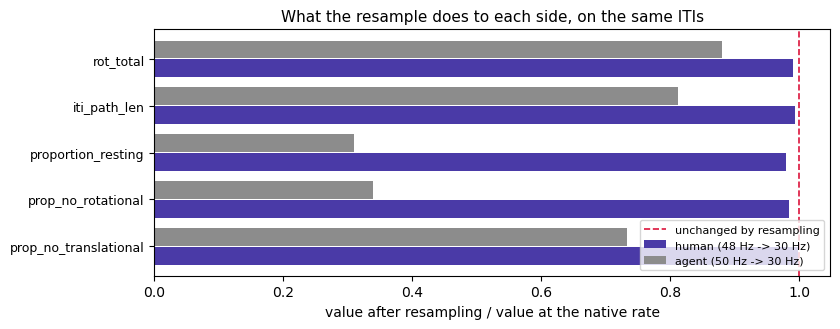

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
sub = effect[effect['metric'] != 'iti_centrality']
y = np.arange(len(sub))
ax.barh(y - 0.2, sub['ratio_human'], height=0.38, color=HUMAN_COLOUR, label='human (48 Hz -> 30 Hz)')
ax.barh(y + 0.2, sub['ratio_agent'], height=0.38, color=AGENT_COLOUR, label='agent (50 Hz -> 30 Hz)')
ax.axvline(1, color='crimson', ls='--', lw=1.2, label='unchanged by resampling')
ax.set_yticks(y); ax.set_yticklabels(sub['metric'], fontsize=9)
ax.set_xlabel('value after resampling / value at the native rate')
ax.set_title('What the resample does to each side, on the same ITIs', fontsize=11)
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

**Interpretation**

**The resample does not treat the two sides alike.** Humans pass through it almost untouched, every
ratio between 0.97 and 1.00. Agents do not: `prop_no_rotational` keeps a third of its value, resting
a third, and the two sums lose 12% and 19%.

The reason is that the effect depends on the signal, not on the ratio of the two rates. A human
moves a mouse smoothly and is often genuinely still for seconds at a time, so a 30 Hz chord across
their trace loses almost nothing. An agent picks one of three discrete actions every 50 Hz frame and
can switch on any of them, so interpolating across two frames averages a stop with a turn and the
stillness disappears.

`iti_centrality` is unchanged on both sides, to three decimals, which is the check that the
resampling itself is faithful: a mean radius cannot move with the sampling rate.

**So the 30 Hz comparison is not the neutral common ground it looks like.** Downsampling the agents
to meet the humans would distort only the side that did not need it, and buy nothing, because the
human numbers are the same either way.

**So the agents stay at 50 Hz, and the humans stay on the tick grid.** That keeps all 40 central
players, since the tick grid is where player 1 exists, and the human ratios say their tick values
are their native values to within 3%. This is the comparison part 2 onwards already reports.

Part 3b reads it. Part 3c then checks it twice: against humans measured natively, and against the
choice we did not make, resampling both sides.

### 3b. The comparison

Humans on the tick grid, which their ratios say costs them nothing, and agents on their own 50 Hz
frames. All 40 central players and all 27 central models.

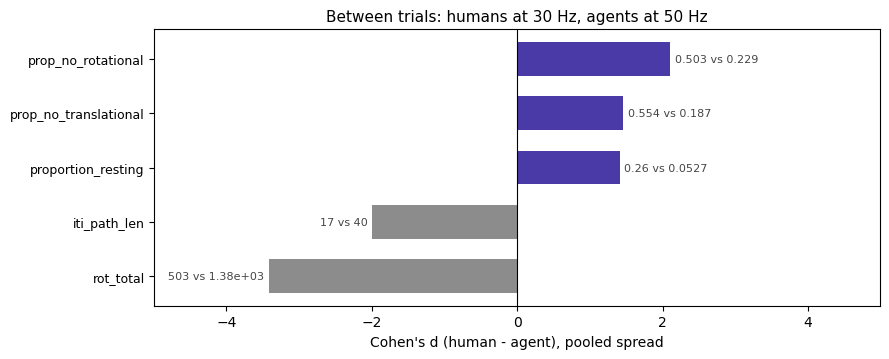

,metric,human_mean,agent_mean,diff,d,ci_lo,ci_hi
0,rot_total,503.199,1383.387,-880.188,-3.418,-1005.264,-752.931
3,prop_no_rotational,0.503,0.229,0.274,2.106,0.208,0.336
4,iti_path_len,17.030,40.041,-23.011,-2.000,-28.031,-17.856
5,prop_no_translational,0.554,0.187,0.366,1.459,0.256,0.477
7,proportion_resting,0.260,0.053,0.207,1.413,0.146,0.272


In [8]:
forest(comparison, ['between trials'], 'Between trials: humans at 30 Hz, agents at 50 Hz')
plt.tight_layout(); plt.show()

display(comparison[comparison['reading'] == 'between trials']
        [['metric', 'human_mean', 'agent_mean', 'diff', 'd', 'ci_lo', 'ci_hi']].round(3))

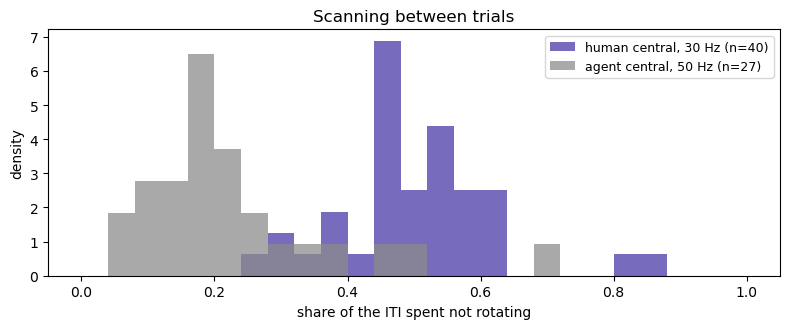

human range 0.250-0.858 (median 0.485)
agent range 0.071-0.689 (median 0.193)
agents above the least-scanning human: 6 of 27
humans below the most-resting agent:   38 of 40


In [9]:
# the spread of the largest difference, player by player and model by model
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 26)
ax.hist(human['prop_no_rotational'], bins=bins, color=HUMAN_COLOUR, alpha=0.75,
        label=f'human central, 30 Hz (n={len(human)})', density=True)
ax.hist(agent['prop_no_rotational'], bins=bins, color=AGENT_COLOUR, alpha=0.75,
        label=f'agent central, 50 Hz (n={len(agent)})', density=True)
ax.set_xlabel('share of the ITI spent not rotating'); ax.set_ylabel('density')
ax.set_title('Scanning between trials'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

h, a = human['prop_no_rotational'], agent['prop_no_rotational']
print(f"human range {h.min():.3f}-{h.max():.3f} (median {h.median():.3f})")
print(f"agent range {a.min():.3f}-{a.max():.3f} (median {a.median():.3f})")
# the groups separate on the mean, so report how far into each other they reach
print(f"agents above the least-scanning human: {(a >= h.min()).sum()} of {len(a)}")
print(f"humans below the most-resting agent:   {(h <= a.max()).sum()} of {len(h)}")

**Interpretation**

Between-trial behaviour holds the largest differences in the whole fingerprint.

- **Agents turn about two and a half times as much in total**, 1383 degrees against 503 over an ITI
  of the same length.
- **Agents cover about two and a half times the ground**, 40.0 units against 17.0.
- **Humans spend about half the ITI not turning at all** (0.50) against the agents' 0.23.
- **Humans rest about five times as often**, 0.26 against 0.05.

The two groups are not disjoint. A few agents rest about as much as the most static humans, which
the 260914 notebook already names as its own within-cluster spread (models 2, 3 and 24 pull the
resting mean). The separation is in the typical member of each group, not in every one.

The obvious reading is that agents scan and humans do not. What part 2 already showed is that this
buys the agents nothing at the moment the walls appear: both sides have a wall in view on about 68%
of trials. That figure is close to what the geometry alone gives, since a 110 degree view over two
lit walls out of eight is a matter of where you happen to be facing.

So constant turning does not improve the *start*. What it changes is the *recovery*: an agent
already rotating when the walls appear sweeps one into view sooner, which is the 0.34 s against
0.59 s in part 2.

### 3c. Two cross-checks

**Does putting the humans on the tick grid change them?** Their ratios say no, but the direct test is
to measure the central players natively and compare. That costs log id 1, so it runs on the 25
central players logged as id 0.

**What would the rejected choice have given?** Resampling both sides to 30 Hz is what a shared grid
would have meant. It is shown here so the size of the distortion is on the record.

In [10]:
# humans measured natively (id 0 only), against the same agents at 50 Hz
h_native = (native_fast.merge(human[['experiment', 'player']], on=['experiment', 'player'])
            .groupby(['experiment', 'player'])[hac.ITI_METRICS].mean().reset_index())
native_comparison = hac.compare_metrics(h_native, agent, hac.ITI_METRICS, n_boot=N_BOOT)

# the choice not made: both sides resampled to 30 Hz
agent_ticks = hac.rebuild_agent_iti(agent_fp, iti_ticks)
agent_ticks = hac.agent_central_models(agent_ticks)
both_ticks = hac.compare_metrics(human, agent_ticks, hac.ITI_METRICS, n_boot=N_BOOT)

check = comparison.set_index('metric').loc[hac.ITI_METRICS, ['human_mean', 'agent_mean', 'd']].rename(
    columns={'human_mean': 'human 30Hz', 'agent_mean': 'agent 50Hz', 'd': 'd (used)'})
check['d (humans native)'] = native_comparison.set_index('metric')['d']
check['agent 30Hz'] = both_ticks.set_index('metric')['agent_mean']
check['d (both 30Hz)'] = both_ticks.set_index('metric')['d']
display(check[['human 30Hz', 'agent 50Hz', 'd (used)', 'd (humans native)',
               'agent 30Hz', 'd (both 30Hz)']].round(3))

print(f"humans measured natively: n = {len(h_native)} of {len(human)} central players")
print("direction unchanged in every column:",
      bool((np.sign(check['d (used)']) == np.sign(check['d (humans native)'])).all()
           and (np.sign(check['d (used)']) == np.sign(check['d (both 30Hz)'])).all()))

,human 30Hz,agent 50Hz,d (used),d (humans native),agent 30Hz,d (both 30Hz)
metric,,,,,,
prop_no_translational,0.554,0.187,1.459,1.646,0.134,1.747
prop_no_rotational,0.503,0.229,2.106,2.364,0.080,3.722
proportion_resting,0.260,0.053,1.413,1.719,0.016,1.743
iti_path_len,17.030,40.041,-2.000,-2.113,32.233,-1.368
rot_total,503.199,1383.387,-3.418,-3.753,1231.574,-2.870


humans measured natively: n = 25 of 40 central players
direction unchanged in every column: True


**Interpretation**

**Measuring the humans natively changes nothing that matters.** The effect sizes move a little,
mostly because the native group is 25 players rather than 40, and every difference keeps its sign
and stays large. So the tick grid is doing the humans no harm, which is what their ratios predicted.

**Resampling both sides would not have reversed anything either, but it would have misreported the
agents.** Every direction survives, so the conclusions are safe under either choice. What does not
survive is the agent numbers themselves: their resting share reads 0.016 against a true 0.053, and
`prop_no_rotational` 0.08 against 0.23. Any statement of the form "agents rest 2% of the ITI" taken
from the resampled table would simply be wrong.

That is the distinction worth keeping. A shared grid here would have been good enough for the
*direction* of a difference and wrong for the *value* of it, and only one of those is what the
between-trial metrics are usually asked for.

## 4. Execution and outcome

How each side gets to the wall once the walls are lit, and what it earns. Latency, route and P(High)
are measured on each side's own wins, so they describe that player rather than their opponent.

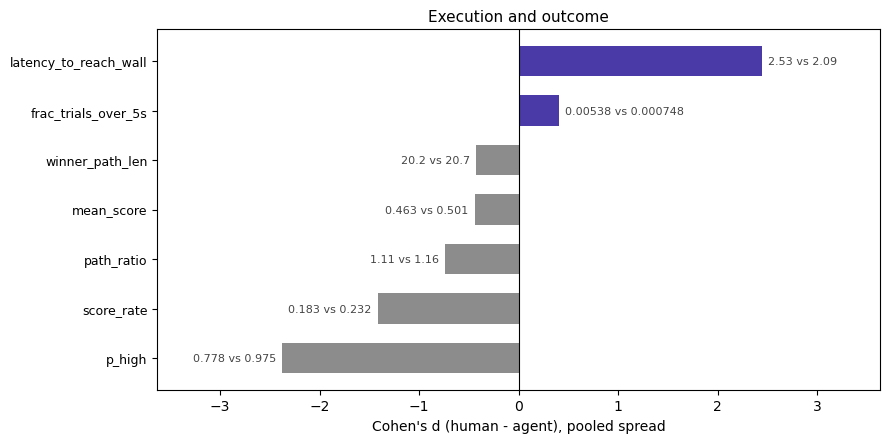

,metric,human_mean,agent_mean,diff,d,ci_lo,ci_hi
1,latency_to_reach_wall,2.532,2.087,0.445,2.448,0.370,0.519
2,p_high,0.778,0.975,-0.196,-2.376,-0.233,-0.158
6,score_rate,0.183,0.232,-0.049,-1.418,-0.063,-0.035
12,path_ratio,1.112,1.164,-0.051,-0.743,-0.078,-0.021
13,mean_score,0.463,0.501,-0.038,-0.442,-0.072,-0.003
14,winner_path_len,20.170,20.732,-0.561,-0.425,-1.085,0.024
15,frac_trials_over_5s,0.005,0.001,0.005,0.406,0.001,0.010


In [11]:
forest(comparison, ['execution', 'outcome'], 'Execution and outcome')
plt.tight_layout(); plt.show()

display(comparison[comparison['reading'].isin(['execution', 'outcome'])]
        [['metric', 'human_mean', 'agent_mean', 'diff', 'd', 'ci_lo', 'ci_hi']].round(3))

In [12]:
# how far each side sits from the geometric floor: a straight run from the centre at 10 units/s
FLOOR_S = mc.ARENA_RADIUS / 10.0
print(f"straight run from the exact centre at 10 units/s: {FLOOR_S:.2f} s")
for name, grp in (('human central', human), ('agent central', agent)):
    lat = grp['latency_to_reach_wall'].mean()
    print(f"  {name:14s} {lat:.3f} s, {lat - FLOOR_S:+.3f} s over the floor "
          f"(route {grp['winner_path_len'].mean():.2f} units, ratio {grp['path_ratio'].mean():.3f})")

straight run from the exact centre at 10 units/s: 1.97 s
  human central  2.532 s, +0.557 s over the floor (route 20.17 units, ratio 1.112)
  agent central  2.087 s, +0.113 s over the floor (route 20.73 units, ratio 1.164)


**Interpretation**

- **Humans take about 0.45 s longer to reach the wall**, 2.53 s against 2.09 s. The agents sit
  roughly a tenth of a second above the floor a straight run from the centre would give; the humans
  sit about half a second above it.
- **Routes are nearly the same length.** `winner_path_len` 20.2 against 20.7, and the human path
  ratio is slightly *better* (1.11 against 1.16). Humans do not take a worse line to the wall. The
  time goes somewhere other than the route, which points at the start of the trial rather than the
  run.
- **Score per second differs by much less than the raw tables suggest.** On one definition it is
  0.18 against 0.23. The raw fingerprints read 0.177 against 0.464, almost all of which was the
  `winner_score` definition rather than anything the players did.
- **P(High) is the largest execution gap**: 0.78 against 0.98. Part 5 is about that.

## 5. P(High), and what the solos say

Central humans take the High wall on 78% of their wins, central agents on 98%. Read on its own that
looks like humans failing to identify or commit to the better wall.

The solo sessions test that directly. A solo player runs the same task with no opponent, so nothing
can contest the wall and there is no reason to settle for Low. If the 78% is a perceptual or
decision failure it should persist in solo. If it is a response to being raced, it should not.

Agent numbers are from social self-play throughout, as no solo agent batch matches this one. Score
and win-based metrics are meaningless in solo, where the player always wins, so only the execution
and perception metrics are read across sessions.

In [13]:
SESSION_METRICS = ['onset_centrality', 'p_high', 'latency_to_reach_wall', 'path_ratio',
                   'winner_path_len', 'frac_visible_at_onset', 'late_latency_to_wall_visible',
                   'prop_no_rotational', 'rot_total', 'proportion_resting']

by_session = pd.DataFrame({
    st: human_fp.query("session_type == @st and group == 'central'")[SESSION_METRICS].mean()
    for st in hc.SESSION_TYPES})
by_session['agent (social)'] = agent[SESSION_METRICS].mean()
display(by_session.round(3))

,solo1,social,solo2,agent (social)
onset_centrality,0.821,0.834,0.833,0.873
p_high,0.937,0.778,0.942,0.975
latency_to_reach_wall,3.324,2.532,3.097,2.087
path_ratio,1.164,1.112,1.141,1.164
winner_path_len,21.710,20.170,21.295,20.732
frac_visible_at_onset,0.653,0.671,0.672,0.661
late_latency_to_wall_visible,0.835,0.590,0.750,0.335
prop_no_rotational,0.567,0.503,0.568,0.229
rot_total,353.295,503.199,413.744,1383.387
proportion_resting,0.368,0.260,0.335,0.053


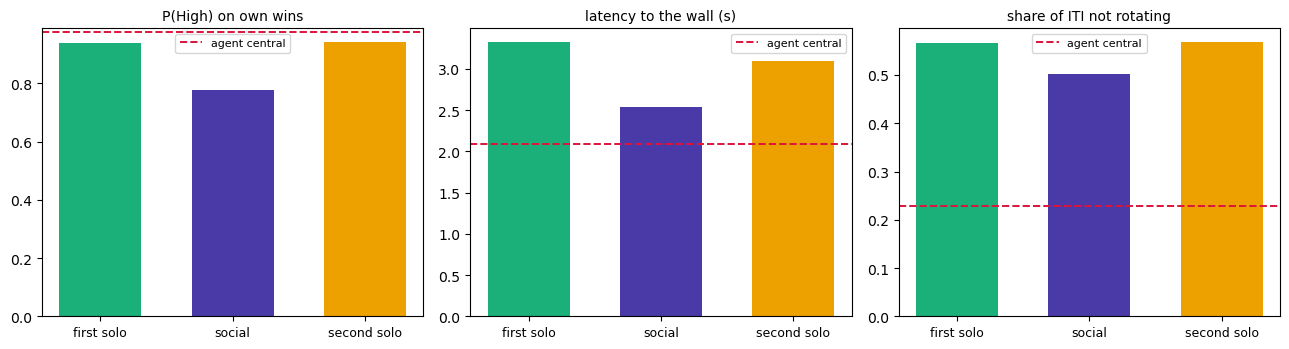

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
panels = [('p_high', 'P(High) on own wins'),
          ('latency_to_reach_wall', 'latency to the wall (s)'),
          ('prop_no_rotational', 'share of ITI not rotating')]
x = np.arange(len(hc.SESSION_TYPES))
for ax, (metric, label) in zip(axes, panels):
    vals = [human_fp.query("session_type == @st and group == 'central'")[metric].mean()
            for st in hc.SESSION_TYPES]
    ax.bar(x, vals, color=[hc.SESSION_PALETTE[s] for s in hc.SESSION_TYPES], width=0.62)
    ax.axhline(agent[metric].mean(), color='crimson', ls='--', lw=1.4, label='agent central')
    ax.set_xticks(x); ax.set_xticklabels([hc.SESSION_LABELS[s] for s in hc.SESSION_TYPES], fontsize=9)
    ax.set_title(label, fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation**

**The 78% is a response to competition, not a deficit.** The same central players take High on 94%
of trials in both solo sessions, against the agents' 98%. Only in social does it fall to 78%.
Whatever else humans do worse, identifying and reaching the High wall is not it.

Two further things show in the same table.

- **Humans are slower in solo than in social** (3.3 s and 3.1 s against 2.5 s), so a good part of
  the human-agent latency gap is urgency rather than capability. Being raced makes humans about
  0.8 s faster, and they are still 0.45 s behind the agents.
- **The scanning gap is not a competition effect.** Humans turn slightly more in social than in
  solo, but nowhere near the agents in any session.

Why the drop happens is a separate question. The obvious candidate is that a central player diverts
to Low when the opponent is going to win the race to High.

In [15]:
# test the obvious candidate at the level this table can support: does a central player's P(High)
# depend on how central their partner is?
soc = human_fp.query("session_type == 'social'")[
    ['experiment', 'player', 'onset_centrality', 'group', 'p_high']]
pairs = soc.merge(soc, on='experiment', suffixes=('', '_partner'))
pairs = pairs[pairs['player'] != pairs['player_partner']]
cen = pairs[pairs['group'] == 'central'].copy()

cen['partner_band'] = pd.cut(cen['onset_centrality_partner'], [-1, 0.3, 0.6, 1.1],
                             labels=['peripheral partner', 'middle partner', 'central partner'])
display(cen.groupby('partner_band', observed=True).agg(
    n=('p_high', 'size'), p_high=('p_high', 'mean'),
    partner_centrality=('onset_centrality_partner', 'mean')).round(3))

r = stats.spearmanr(cen['onset_centrality_partner'], cen['p_high'])
print(f"Spearman(partner centrality, own P(High)) = {r.statistic:.3f}, p = {r.pvalue:.3f}, n = {len(cen)}")

,n,p_high,partner_centrality
partner_band,,,
peripheral partner,1,0.864,0.251
middle partner,6,0.705,0.479
central partner,33,0.789,0.777


Spearman(partner centrality, own P(High)) = 0.077, p = 0.635, n = 40


**Interpretation**

**It is not explained by where the partner waits.** The correlation is flat and its p value is far
from significant.

That test is weak, and it is weak for a structural reason. Partners resemble each other on this axis
(`strategy_characterisation.ipynb` part 6d), so a central player almost always faces another central
player: only one of the 40 had a peripheral partner. The design cannot separate the two at player
level.

The more likely level is the trial, not the player. A central player diverting to Low because *on
this trial* the opponent broke for High would leave no trace in a player-level average. Testing it
needs each trial's inferred loser choice (`analysis/loser_inferred_choice.py`) against the winner's
wall, which is the natural next step and is not done here.

## 6. Does the grouping rule matter?

The two sides were grouped by different rules. Humans are the top 20% of players ranked within their
session, which is what `player_fingerprint.ipynb` reports. Agents are the main cluster, which is
where the batch happens to sit.

The value-matched alternative takes only the human players whose mean onset centrality falls inside
the agent cluster's own range, so both groups occupy the same stretch of the axis.

In [16]:
native = human_fp.query("session_type == @PRIMARY_SESSION and group == 'central'")
banded = hac.human_central_players(hc.player_table(onset), PRIMARY_SESSION, rule='band', band=BAND)
banded = human_fp.merge(banded[['experiment', 'player', 'session_type']],
                        on=['experiment', 'player', 'session_type'], how='inner')

both = hac.compare_metrics(native, agent, METRICS, n_boot=N_BOOT).set_index('metric')[['d']].rename(
    columns={'d': 'd (top 20%)'})
both['d (value-matched)'] = hac.compare_metrics(banded, agent, METRICS, n_boot=N_BOOT
                                                ).set_index('metric')['d']
both['human n'] = f"{len(native)} / {len(banded)}"
display(both.round(3))

rho = stats.spearmanr(both['d (top 20%)'], both['d (value-matched)'])
print(f"rank agreement between the two rules: Spearman {rho.statistic:.3f} over {len(both)} metrics")

,d (top 20%),d (value-matched),human n
metric,,,
rot_total,-3.418,-3.285,40 / 27
latency_to_reach_wall,2.448,3.107,40 / 27
p_high,-2.376,-2.273,40 / 27
prop_no_rotational,2.106,2.102,40 / 27
iti_path_len,-2.000,-2.418,40 / 27
prop_no_translational,1.459,1.776,40 / 27
score_rate,-1.418,-1.947,40 / 27
proportion_resting,1.413,1.662,40 / 27
onset_centrality,-1.182,-0.874,40 / 27


rank agreement between the two rules: Spearman 0.981 over 18 metrics


**Interpretation**

The two rules give the same picture. Every large difference stays large and keeps its sign, and the
ordering barely moves. Narrowing the human group to the agent band shifts its mean onset centrality
from 0.834 to 0.851 and changes no conclusion.

So none of the results above is an artefact of how the two groups were picked.

## What this says

Holding the strategy fixed, central humans and central agents differ in three separable ways, and
agree on a fourth that matters as much.

1. **They see the same thing at the decision point.** A wall is in view at onset on about 68% of
   trials for both. The difference between them is not perceptual access.
2. **Humans barely scan between trials; agents scan constantly.** The largest gap in the
   fingerprint: agents turn and travel about two and a half times as much. It survives every
   sampling choice tested. It does not improve the agents' start, only their recovery when they
   have to search (0.34 s against 0.59 s).
3. **Humans are about 0.45 s slower to the wall**, but take an equally direct route. Comparing
   across sessions, most of a second of that is urgency: the same players are 0.8 s slower again in
   solo, where nothing is racing them.
4. **Humans take Low far more often, but only when contested.** 78% High in social against 94% in
   both solos, with the agents at 98%. Read across sessions this is a competitive response, not a
   failure to find or commit to the better wall.

Point 4 is the one that bears on the wider question. The agents almost never take the Low wall. They
were trained only against copies of themselves, where both agents start equidistant from both walls
and there is no positional reason to settle for Low. Human central players do settle, and only when
someone is racing them. Whether that is a good response or a costly one is not settled here: score
per second is 0.18 against 0.23 on a common definition, but the human number is earned against a
mixed population of opponents while the agent number comes from self-play, so the two are not a
fair league table.

## What this does not settle

- **Why P(High) drops under competition.** The partner's waiting position does not explain it, but
  the test is badly underpowered because partners resemble each other. The trial-level test is the
  one to run.
- **The self-play ceiling.** Every agent number comes from a model playing a copy of itself. None of
  these agents has met an opponent that behaves differently, so their 98% may be a fact about
  self-play rather than about central strategy.
- **Whether scanning is worth it.** Agents scan far more and recover faster, but start no better.
  Nothing here prices that against its cost.
- **The human between-trial metrics are on the 30 Hz grid, not the logged frames.** Their ratios say
  this costs at most 3%, and part 3c confirms it against the 25 central players who have a native
  trace, but the other 15 are taken on that evidence rather than measured. Social log id 1 has no
  native trace, and these metrics are step differences, so the recovery cannot be interpolated back
  up for them the way it is for the frame-level ones.
- **The two populations are not matched on anything but centrality.** Humans play about 135 social
  trials, agents 198; humans see forced trials and agents do not; humans get a brightness cue at
  trial start that agents have no sensor for.